# Phase 1: Image Processing
This notebook completes Phase 1 for the Sentinel-2 Da Nang dataset.

The workflow now processes both exported AOI pieces (`above` and `below`) for both dates (2024-04-11 and 2026-04-11), computes NDVI from the Red (`B04`) and Near-Infrared (`B08`) bands, compares the two dates quantitatively and visually, and applies denoising plus contrast enhancement to true-color imagery.

All plots used in the report are exported to `../output`.


In [1]:
import csv
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

# Paths are relative to this notebook when run from the works directory.
dataset_dir = Path("../dataset")
output_dir = Path("../output")
output_dir.mkdir(parents=True, exist_ok=True)

# Two Sentinel-2 dates selected in the same month to reduce seasonal effects.
dates = {
    "2024": {"folder": dataset_dir / "2024_04_11", "suffix": "2024", "label": "April 11, 2024"},
    "2026": {"folder": dataset_dir / "2026_04_11", "suffix": "2026", "label": "April 11, 2026"},
}

# The AOI was exported in two pieces, so Phase 1 evaluates both pieces.
crops = {
    "above": "Upper AOI crop",
    "below": "Lower AOI crop",
}

print(f"Dataset directory: {dataset_dir.resolve()}")
print(f"Output directory: {output_dir.resolve()}")


Dataset directory: /home/dacekey/CPV301_SUM26/main/L27_Assignment_*/dataset
Output directory: /home/dacekey/CPV301_SUM26/main/L27_Assignment_*/output


In [2]:
def find_one(folder, pattern):
    matches = sorted(folder.glob(pattern))
    if not matches:
        raise FileNotFoundError(f"No file matching {pattern!r} in {folder}")
    if len(matches) > 1:
        print(f"Warning: multiple matches for {pattern!r} in {folder}; using {matches[0].name}")
    return matches[0]


def crop_folder(date_key, crop_key):
    config = dates[date_key]
    return config["folder"] / f"{crop_key}_{config['suffix']}"


def load_band(path):
    band = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if band is None:
        raise FileNotFoundError(f"Cannot load image: {path}")
    if band.ndim != 2:
        raise ValueError(f"Expected a single-band image for {path}, got shape {band.shape}")
    return band.astype(np.float32)


def calculate_ndvi(red_band, nir_band):
    if red_band.shape != nir_band.shape:
        raise ValueError(f"Band shape mismatch: Red {red_band.shape}, NIR {nir_band.shape}")
    denominator = nir_band + red_band
    return np.divide(
        nir_band - red_band,
        denominator,
        out=np.zeros_like(nir_band, dtype=np.float32),
        where=denominator != 0,
    )


def normalize_to_uint8(image):
    return cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)


def load_true_color(path):
    image = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if image is None:
        raise FileNotFoundError(f"Cannot load image: {path}")
    if image.ndim != 3 or image.shape[2] < 3:
        raise ValueError(f"Expected a 3-channel true-color image for {path}, got shape {image.shape}")
    rgb = cv2.cvtColor(image[:, :, :3], cv2.COLOR_BGR2RGB)
    return normalize_to_uint8(rgb)


def apply_filter_pipeline(rgb_image):
    # Gaussian blur reduces high-frequency sensor noise but can soften sharp boundaries.
    denoised = cv2.GaussianBlur(rgb_image, (5, 5), 0)

    # Equalize only the brightness channel to improve contrast while preserving hue better.
    hsv = cv2.cvtColor(denoised, cv2.COLOR_RGB2HSV)
    h, s, v = cv2.split(hsv)
    v_equalized = cv2.equalizeHist(v)
    enhanced = cv2.cvtColor(cv2.merge((h, s, v_equalized)), cv2.COLOR_HSV2RGB)
    return denoised, enhanced


def save_figure(fig, filename):
    path = output_dir / filename
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved: {path}")
    return path


In [3]:
ndvi_data = {}
stats_rows = []

for crop_key, crop_label in crops.items():
    for date_key, date_info in dates.items():
        folder = crop_folder(date_key, crop_key)
        red_path = find_one(folder, "*B04*.tiff")
        nir_path = find_one(folder, "*B08*.tiff")

        red = load_band(red_path)
        nir = load_band(nir_path)
        ndvi = calculate_ndvi(red, nir)
        ndvi_data[(crop_key, date_key)] = ndvi

        stats_rows.append({
            "crop": crop_key,
            "date": date_key,
            "shape": f"{ndvi.shape[0]}x{ndvi.shape[1]}",
            "min": float(np.min(ndvi)),
            "max": float(np.max(ndvi)),
            "mean": float(np.mean(ndvi)),
            "std": float(np.std(ndvi)),
        })

stats_path = output_dir / "phase1_ndvi_statistics.csv"
with stats_path.open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["crop", "date", "shape", "min", "max", "mean", "std"])
    writer.writeheader()
    writer.writerows(stats_rows)

print(f"Saved: {stats_path}")
print("\nNDVI summary statistics")
print(f"{'Crop':<8} {'Date':<6} {'Shape':<10} {'Min':>9} {'Max':>9} {'Mean':>9} {'Std':>9}")
for row in stats_rows:
    print(
        f"{row['crop']:<8} {row['date']:<6} {row['shape']:<10} "
        f"{row['min']:>9.4f} {row['max']:>9.4f} {row['mean']:>9.4f} {row['std']:>9.4f}"
    )


Saved: ../output/phase1_ndvi_statistics.csv

NDVI summary statistics
Crop     Date   Shape            Min       Max      Mean       Std
above    2024   252x774      -1.0000    0.8590    0.0711    0.6043
above    2026   252x774      -1.0000    0.8496    0.1769    0.4408
below    2024   313x743      -1.0000    0.8526    0.1114    0.5089
below    2026   313x743      -0.7572    0.8445    0.1887    0.3933


Saved: ../output/phase1_ndvi_heatmaps.png


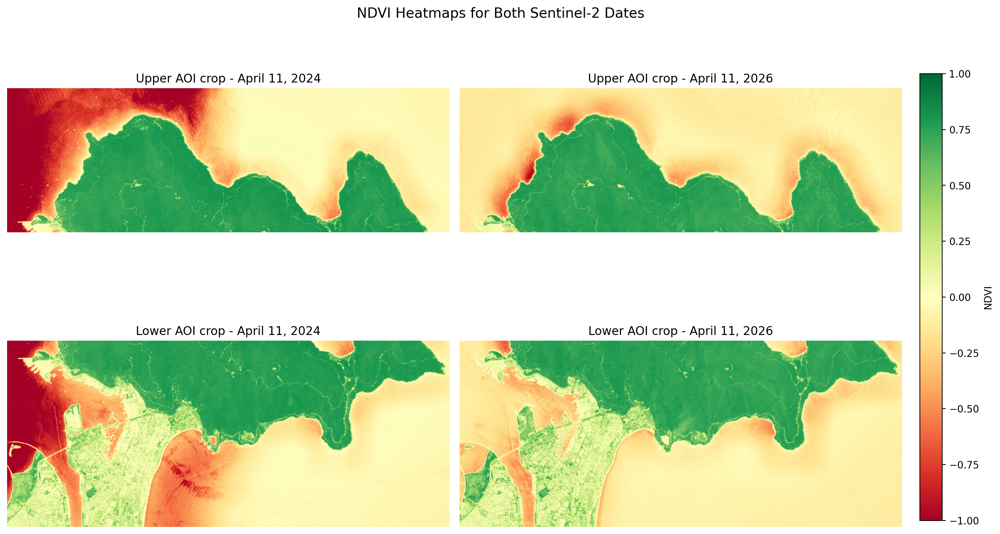

In [4]:
fig, axes = plt.subplots(len(crops), len(dates), figsize=(14, 8), constrained_layout=True)

for row_idx, (crop_key, crop_label) in enumerate(crops.items()):
    for col_idx, (date_key, date_info) in enumerate(dates.items()):
        ax = axes[row_idx, col_idx]
        im = ax.imshow(ndvi_data[(crop_key, date_key)], cmap="RdYlGn", vmin=-1, vmax=1)
        ax.set_title(f"{crop_label} - {date_info['label']}")
        ax.axis("off")

fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.025, pad=0.02, label="NDVI")
fig.suptitle("NDVI Heatmaps for Both Sentinel-2 Dates", fontsize=14)
save_figure(fig, "phase1_ndvi_heatmaps.png")
plt.show()


Saved: ../output/phase1_ndvi_difference.png
Mean NDVI change by AOI crop
- above: +0.1059 (increase)
- below: +0.0773 (increase)


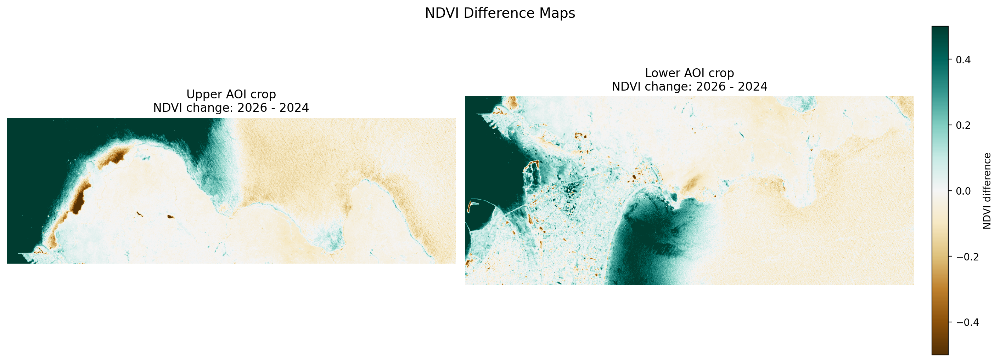

In [5]:
fig, axes = plt.subplots(1, len(crops), figsize=(14, 5), constrained_layout=True)
mean_changes = []

for ax, (crop_key, crop_label) in zip(axes, crops.items()):
    ndvi_2024 = ndvi_data[(crop_key, "2024")]
    ndvi_2026 = ndvi_data[(crop_key, "2026")]
    if ndvi_2024.shape != ndvi_2026.shape:
        raise ValueError(f"Cannot compare dates for {crop_key}: {ndvi_2024.shape} vs {ndvi_2026.shape}")

    diff = ndvi_2026 - ndvi_2024
    mean_delta = float(np.mean(diff))
    mean_changes.append((crop_key, mean_delta))

    im = ax.imshow(diff, cmap="BrBG", vmin=-0.5, vmax=0.5)
    ax.set_title(f"{crop_label}\nNDVI change: 2026 - 2024")
    ax.axis("off")

fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.035, pad=0.02, label="NDVI difference")
fig.suptitle("NDVI Difference Maps", fontsize=14)
save_figure(fig, "phase1_ndvi_difference.png")
plt.show()

print("Mean NDVI change by AOI crop")
for crop_key, mean_delta in mean_changes:
    direction = "increase" if mean_delta > 0 else "decrease" if mean_delta < 0 else "no net change"
    print(f"- {crop_key}: {mean_delta:+.4f} ({direction})")


Saved: ../output/phase1_ndvi_mean_comparison.png


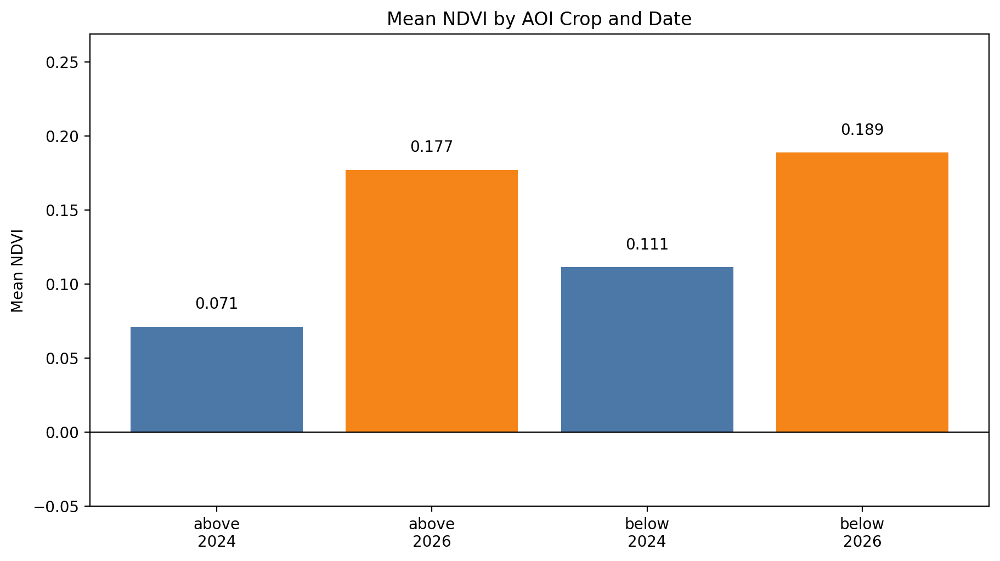

In [6]:
labels = []
means = []
colors = []
for crop_key, crop_label in crops.items():
    for date_key in dates:
        row = next(r for r in stats_rows if r["crop"] == crop_key and r["date"] == date_key)
        labels.append(f"{crop_key}\n{date_key}")
        means.append(row["mean"])
        colors.append("#4c78a8" if date_key == "2024" else "#f58518")

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
bars = ax.bar(labels, means, color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Mean NDVI")
ax.set_title("Mean NDVI by AOI Crop and Date")
ax.set_ylim(min(-0.05, min(means) - 0.05), max(means) + 0.08)
for bar, value in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.01, f"{value:.3f}", ha="center", va="bottom")

save_figure(fig, "phase1_ndvi_mean_comparison.png")
plt.show()


## Denoising and Contrast Enhancement
Gaussian blur is used as the denoising/smoothing filter because it suppresses small high-frequency sensor variation in the true-color image. The main trade-off is that very thin boundaries such as roads, coastlines, and small construction edges can become slightly softer.

Histogram equalization is used for contrast enhancement. It is applied to the HSV value channel instead of directly to RGB channels, which improves brightness contrast while reducing color distortion. The trade-off is that weak noise or compression artifacts may become more visible in low-texture regions.


Saved: ../output/phase1_filter_contrast_comparison.png


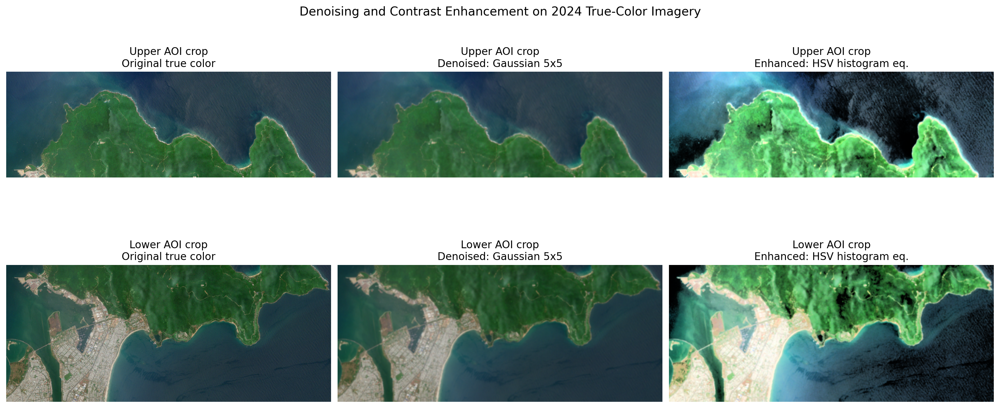

In [7]:
filter_results = {}

for crop_key, crop_label in crops.items():
    folder = crop_folder("2024", crop_key)
    true_color_path = find_one(folder, "*True_color*.tiff")
    original = load_true_color(true_color_path)
    denoised, enhanced = apply_filter_pipeline(original)
    filter_results[crop_key] = {
        "original": original,
        "denoised": denoised,
        "enhanced": enhanced,
    }

fig, axes = plt.subplots(len(crops), 3, figsize=(16, 7), constrained_layout=True)
columns = [
    ("original", "Original true color"),
    ("denoised", "Denoised: Gaussian 5x5"),
    ("enhanced", "Enhanced: HSV histogram eq."),
]

for row_idx, (crop_key, crop_label) in enumerate(crops.items()):
    for col_idx, (image_key, title) in enumerate(columns):
        ax = axes[row_idx, col_idx]
        ax.imshow(filter_results[crop_key][image_key])
        ax.set_title(f"{crop_label}\n{title}")
        ax.axis("off")

fig.suptitle("Denoising and Contrast Enhancement on 2024 True-Color Imagery", fontsize=14)
save_figure(fig, "phase1_filter_contrast_comparison.png")
plt.show()


## Phase 1 Notes
The NDVI maps use the required point operation on matching Red and NIR bands for both acquisition dates. The notebook checks band shape consistency before computing NDVI, reports min/max/mean/std values, and exports all plots for the written report.

The two AOI pieces are not stitched in Phase 1 because stitching belongs to Phase 3. Therefore, the upper and lower crops are processed and compared independently here.
